# Milestone 3: baseline walkthrough
**Team ML Musketeers (Group 21) - CSCI 3052U, Fall 2026**

This notebook builds on the group's exploratory notebook (`01_m2_eda.ipynb`: crosstabs of Target by gender, scholarship, tuition, debtor, displaced, day/evening attendance and boxplots of grades, age and macroeconomic variables). It does not repeat that EDA. It (1) runs the baseline pipeline, (2) shows the results table, and (3) checks how the baseline behaves for the same groups the EDA looked at.

Codings follow the dataset descriptor (Realinho et al., 2022, Appendix A): **Gender 1 = male, 0 = female; Daytime/evening attendance 1 = daytime, 0 = evening**; yes/no variables 1 = yes.

Run from the repository root: `python scripts/run_baseline.py` and `python scripts/subgroup_baseline.py` produce everything shown here.

In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
print(json.load(open('../results/run_log.json')))

{'script': 'scripts/run_baseline.py', 'seed': 42, 'dataset_md5': '9b2b50f41d0cefbbc3e8222d60032d91', 'split': {'train': 3096, 'val': 664, 'test': 664}, 'test_set_used': False, 'tuned_C_by_feature_set': {'early': 1, 'full': 1}, 'cv': {'folds': 5, 'repeats': 3}, 'software': {'python': '3.12.3', 'pandas': '3.0.2', 'numpy': '2.4.4', 'scikit-learn': '1.8.0', 'scipy': '1.17.1'}, 'runtime_seconds': 21.9}


## 1. Baseline table (validation set; CV on the training set)
Generated by `scripts/run_baseline.py`. Primary metric: macro-F1.

In [2]:
t = pd.read_csv('../results/baseline_table.csv')
t[t.model != 'Logistic regression (tuned, C=1)'][['feature_set','model','macro_F1','accuracy','recall_Dropout','recall_Enrolled','cv_macro_F1_mean','cv_macro_F1_sd']].round(3)

,feature_set,model,macro_F1,accuracy,recall_Dropout,recall_Enrolled,cv_macro_F1_mean,cv_macro_F1_sd
0,early,Majority class,0.222,0.500,0.000,0.000,0.222,0.000
1,early,Stratified random (seed 42),0.313,0.374,0.319,0.126,0.333,0.020
2,early,Logistic regression (C=1),0.651,0.736,0.714,0.319,0.659,0.011
4,early,Decision tree (depth 5),0.549,0.703,0.690,0.084,0.576,0.026
5,full,Majority class,0.222,0.500,0.000,0.000,0.222,0.000
6,full,Stratified random (seed 42),0.313,0.374,0.319,0.126,0.333,0.020
7,full,Logistic regression (C=1),0.705,0.773,0.751,0.420,0.697,0.015
9,full,Decision tree (depth 5),0.602,0.720,0.634,0.193,0.639,0.016


## 2. Reproduction check against the Milestone 2 memo

In [3]:
pd.read_csv('../results/reproduction_check.csv')

,feature_set,model,expected_macro_F1,reproduced_macro_F1,delta_macro_F1,expected_acc,reproduced_acc,delta_acc
0,early,Majority class,0.222,0.222,0.0,0.500,0.500,0.0
1,early,Stratified random (seed 42),0.313,0.313,0.0,0.373,0.373,0.0
2,early,Logistic regression (C=1),0.651,0.651,-0.0,0.736,0.736,0.0
3,early,Decision tree (depth 5),0.549,0.549,0.0,0.703,0.703,0.0
4,full,Majority class,0.222,0.222,0.0,0.500,0.500,0.0
5,full,Stratified random (seed 42),0.313,0.313,0.0,0.373,0.373,0.0
6,full,Logistic regression (C=1),0.705,0.705,-0.0,0.773,0.773,-0.0
7,full,Decision tree (depth 5),0.602,0.602,-0.0,0.720,0.720,-0.0


## 3. Discrepancy probes

In [4]:
pd.read_csv('../results/discrepancy_probes.csv')

,probe,macro_F1,delta_vs_pipeline,note
0,LogReg max_iter=100 (sklearn default) instead of 3000,0.6508,0.0000,0 convergence warning(s)
1,"Preprocessing fit on ALL rows (leakage, do not use)",0.6492,-0.0017,shows leakage effect is small here but is still a protocol error
2,Stratified random over 10 seeds (mean),0.3372,0.0242,"sd 0.015, range 0.316-0.372; seed 42 gives 0.313"


## 4. Does the baseline treat the EDA groups equally?
Out-of-fold predictions from logistic regression (early features) on train + validation rows (3,760 students; the test set is untouched). The group EDA showed large differences in dropout *rate* between these groups; this table shows whether the *baseline* detects dropouts equally well in each.

In [5]:
s = pd.read_csv('../results/subgroup_baseline.csv'); s.round(3)

,group,n,dropout_rate,accuracy,macro_F1,dropout_recall,dropout_precision
0,All (train+val),3760,0.321,0.746,0.660,0.745,0.777
1,Female,2448,0.254,0.764,0.663,0.699,0.774
2,Male,1312,0.446,0.711,0.641,0.793,0.780
3,Evening attendance,406,0.431,0.732,0.627,0.800,0.828
4,Daytime attendance,3354,0.308,0.748,0.662,0.736,0.768
5,Scholarship holder,936,0.129,0.808,0.548,0.446,0.651
6,No scholarship,2824,0.385,0.725,0.663,0.778,0.787
7,Tuition up to date,3314,0.248,0.728,0.635,0.633,0.710
8,Tuition NOT up to date,446,0.863,0.874,0.491,0.984,0.892
9,Debtor,413,0.627,0.760,0.636,0.911,0.834


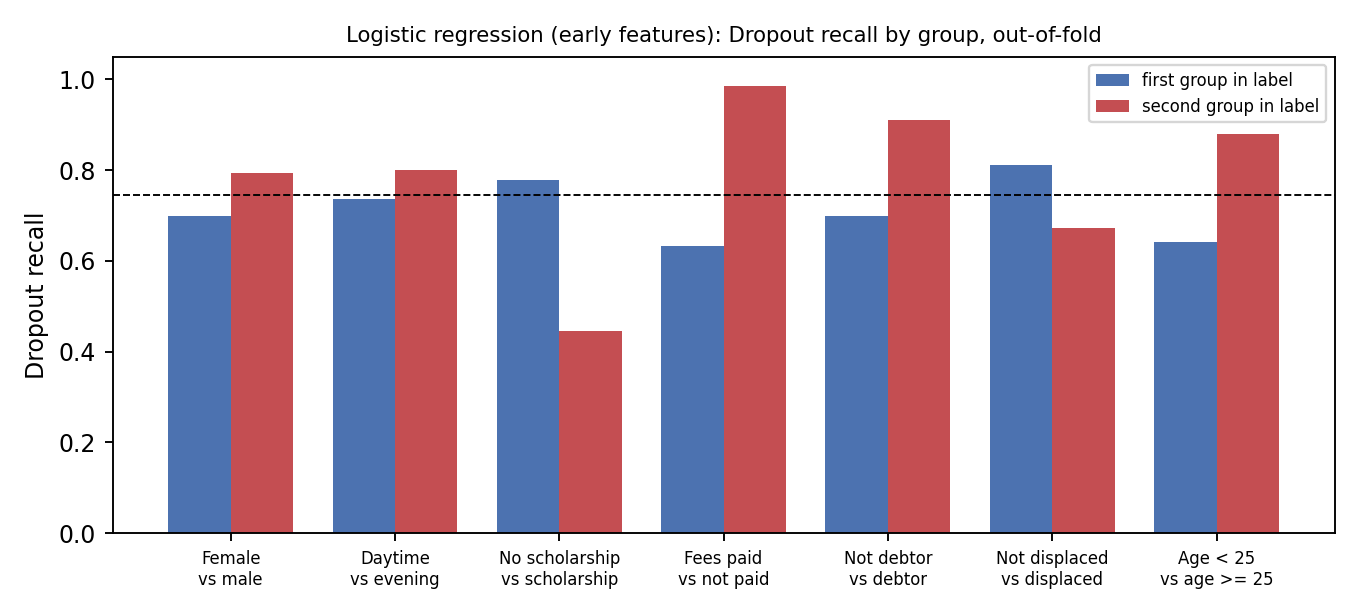

In [6]:
display(Image('../figures/subgroup_dropout_recall.png'))

**Reading the table (what it does and does not show)**
- Dropout recall is 0.98 for students whose tuition is **not** up to date (n=446, 86% of them drop out) but only 0.63 for students whose tuition is up to date, so much of the baseline's Dropout detection comes from the fees variable. The Milestone 5 ablation without financial variables will test this.
- Scholarship holders are rarely dropouts (12.9%) and the baseline finds only 45% of those who do.
- Recall also differs by age (0.88 for age >= 25 vs 0.64 for younger students) and by gender (0.79 male vs 0.70 female). These are descriptive gaps with overlapping uncertainty for small groups (international n=93); they are not evidence of causes.
- Group sizes matter: differences for groups under about 500 students should be read cautiously.

## 5. Confusion matrix (logistic regression, early features, validation)

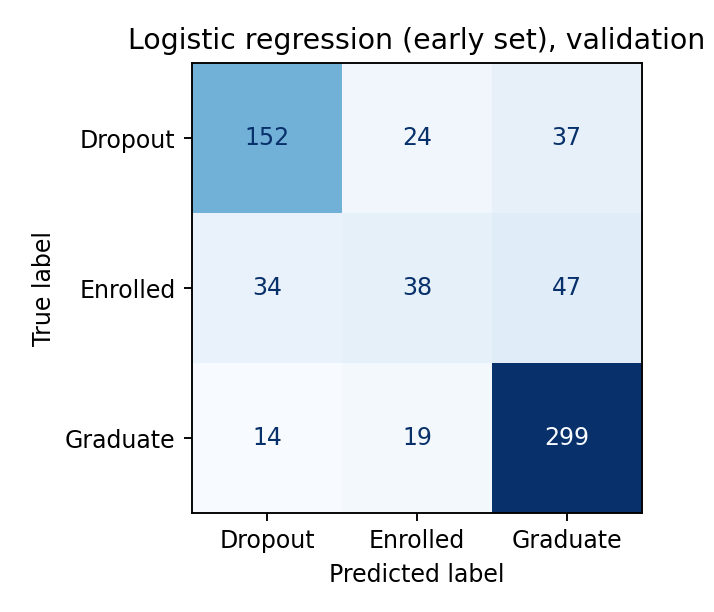

In [7]:
display(Image('../figures/confusion_matrix_logreg_early.png'))